In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

In [11]:
path = '../mitbih_database/'
print(os.path.exists(path))
print(os.path.isdir(path))

True
True


In [3]:
classes = ['N', 'L', 'R', 'A', 'V']

In [4]:
records = list()
annotations = list()

In [12]:
filenames = next(os.walk(path))[2]

for f in filenames:
    filename, file_extension = f.split('.')
    
    if file_extension == 'csv':
        records.append(path + f)
    else:
        annotations.append(path + f)
        
print(records[0])
print(annotations[0])

../mitbih_database/100_record.csv
../mitbih_database/100_annotation.txt


In [17]:
data = pd.read_csv(records[0])

print(data.head())
print(data.shape)

   sample #   MLII     V5
0         0 -0.145 -0.065
1         1 -0.145 -0.065
2         2 -0.145 -0.065
3         3 -0.145 -0.065
4         4 -0.145 -0.065
(650000, 3)


In [18]:
signal = data['MLII'].iloc[:5000]

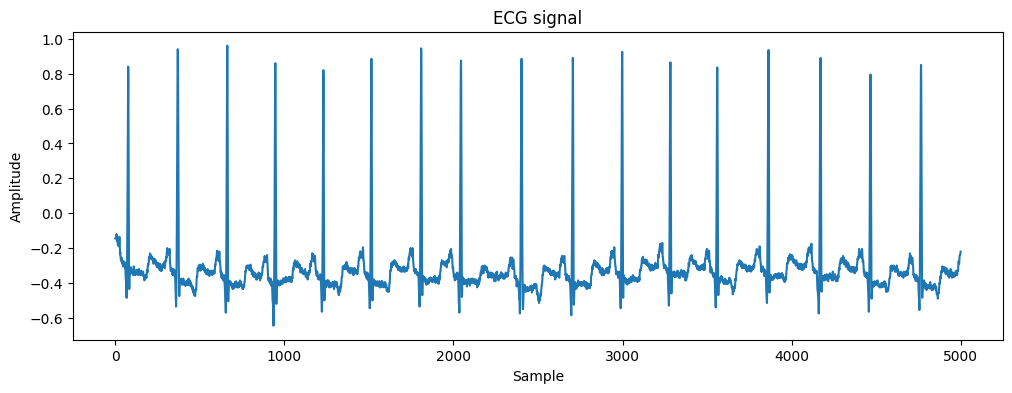

In [19]:
plt.figure(figsize=(12, 4))
plt.plot(signal)
plt.title('ECG signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()

In [20]:
train_size = int(len(signal) * 0.8)

train = signal[:train_size]
test = signal[train_size:]

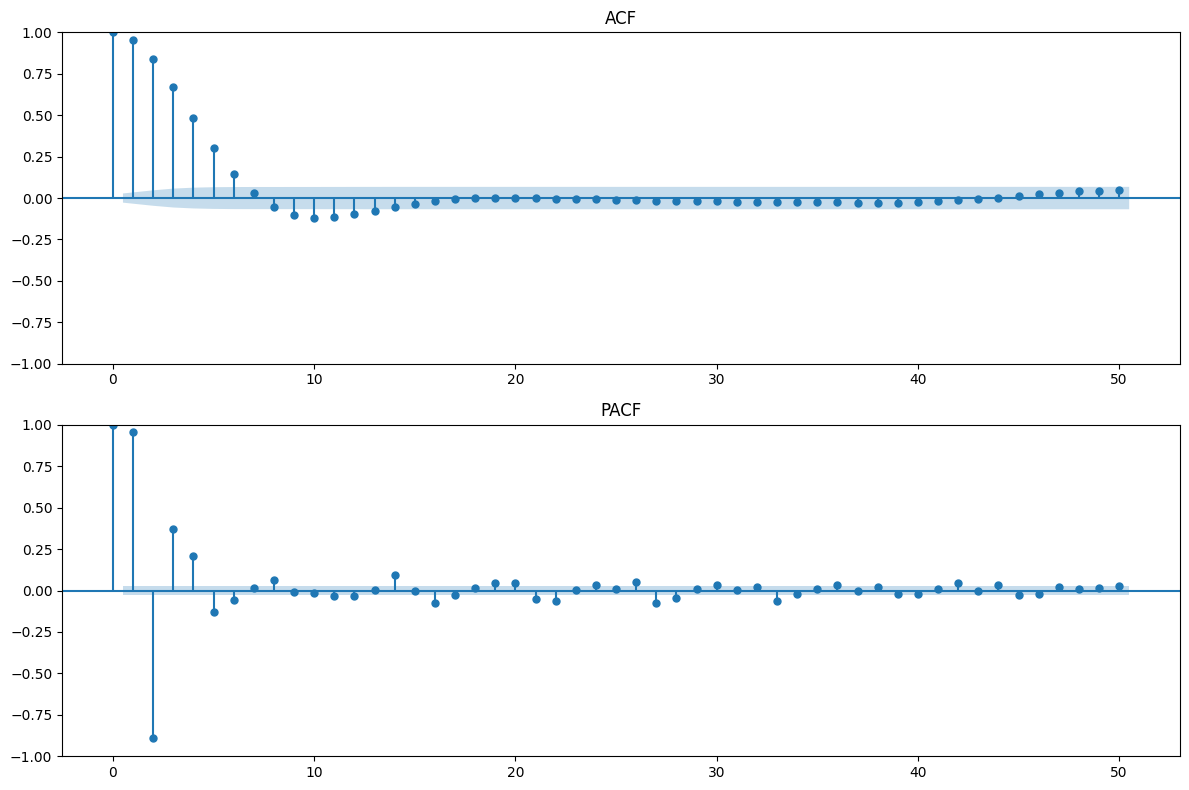

In [21]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(signal, ax=ax[0], lags=50)
ax[0].set_title('ACF')

plot_pacf(signal, ax=ax[1], lags=50)
ax[1].set_title('PACF')

plt.tight_layout()
plt.show()

In [22]:
model = ARIMA(train, order=(2, 0, 0))
model_fit = model.fit()

predictions = []

history = list(train)

for value in test:
    model = ARIMA(history, order=(2, 0, 0))
    model_fit = model.fit()

    prediction = model_fit.forecast(steps=1)[0]
    predictions.append(prediction)

    history.append(value)

In [23]:
residuals = np.array(test) - np.array(predictions)

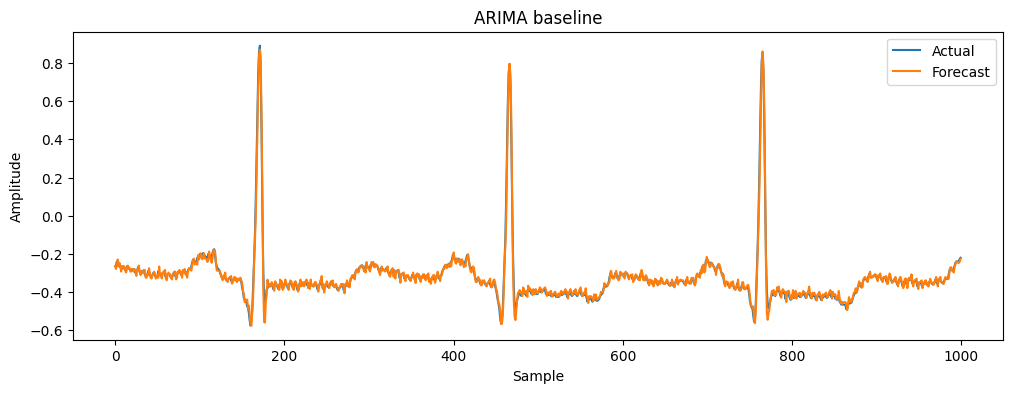

In [24]:
plt.figure(figsize=(12, 4))

plt.plot(test.values, label='Actual')
plt.plot(predictions, label='Forecast')

plt.title('ARIMA baseline')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

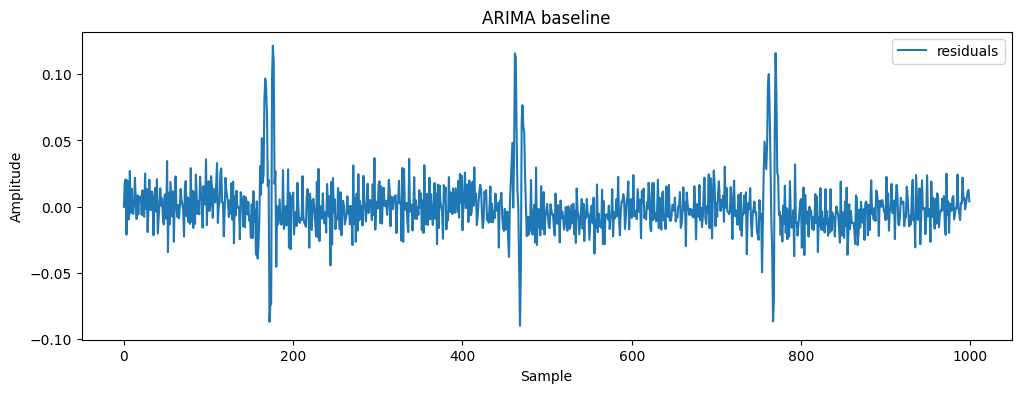

In [25]:
plt.figure(figsize=(12, 4))

plt.plot(residuals, label='residuals')

plt.title('ARIMA baseline')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

'../mitbih_database/100annotations.txt'